# Import Libraries

In [1]:
import os
import math
import time
import random
import shutil
import itertools
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import pwlf
from multiprocessing import Pool, cpu_count
from tqdm import tqdm, trange

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import brevitas.nn as qnn
from brevitas.nn import QuantLinear, QuantReLU, QuantConv2d
from brevitas.inject.enum import QuantType
from brevitas.quant_tensor.int_quant_tensor import IntQuantTensor
from brevitas.function.ops_ste import round_ste
from brevitas.quant import Int8WeightPerChannelFloat

from GRAUApproxToolkit import GRAU_Linear, GRAU_Conv2D, GRAU_ResConv2D, extend_min_max_ranges

# Network Definition

#### Channel number and precision in each area listed here for the ResNet-18 used in ImageNet classification

In [2]:
# -------- Stem --------
kernel_num_CONV_layer_0_0 = 64

# -------- Stage 1 --------
kernel_num_CONV_layer_1_0 = 64
kernel_num_CONV_layer_1_1 = 64
kernel_num_CONV_layer_1_2 = 64
kernel_num_CONV_layer_1_3 = 64

# -------- Stage 2 --------
kernel_num_CONV_layer_2_0 = 128
kernel_num_CONV_layer_2_1 = 128
kernel_num_CONV_layer_2_2 = 128
kernel_num_CONV_layer_2_3 = 128
kernel_num_CONV_layer_2_ds = 128

# -------- Stage 3 --------
kernel_num_CONV_layer_3_0 = 256
kernel_num_CONV_layer_3_1 = 256
kernel_num_CONV_layer_3_2 = 256
kernel_num_CONV_layer_3_3 = 256
kernel_num_CONV_layer_3_ds = 256

# -------- Stage 4 --------
kernel_num_CONV_layer_4_0 = 512
kernel_num_CONV_layer_4_1 = 512
kernel_num_CONV_layer_4_2 = 512
kernel_num_CONV_layer_4_3 = 512
kernel_num_CONV_layer_4_ds = 512

neuron_num_OUT_layer = 1000

precision_CONV_layer_0_0 = 8

precision_CONV_layer_1_0 = 8
precision_CONV_layer_1_1 = 8
precision_CONV_layer_1_2 = 8
precision_CONV_layer_1_3 = 8

precision_CONV_layer_2_0 = 8
precision_CONV_layer_2_1 = 8
precision_CONV_layer_2_2 = 8
precision_CONV_layer_2_3 = 8
precision_CONV_layer_2_ds = 8

precision_CONV_layer_3_0 = 8
precision_CONV_layer_3_1 = 8
precision_CONV_layer_3_2 = 8
precision_CONV_layer_3_3 = 8
precision_CONV_layer_3_ds = 8

precision_CONV_layer_4_0 = 8
precision_CONV_layer_4_1 = 8
precision_CONV_layer_4_2 = 8
precision_CONV_layer_4_3 = 8
precision_CONV_layer_4_ds = 8

precision_OUT_layer = 8

#### Hyperparameters setting here.

In [3]:
epochs = 90
warmup = 10
batch_sizes = [512]
dropout_rates = [0.0]
lr_max_pool = [0.01]
lr_min_pool = [0.00001]
weight_decay = 1e-4

In [4]:
fit_segment_num = 6
fit_points_num = 1000

#### GPU selection. After decided which GPU to train, don't change it before completing the training

In [5]:
GPU_device = "cuda:1"

#### Training data output folder path, for different network model setting, please change the name of save_path

In [6]:
save_path = "ResNet18_ReLU_SiLU_8bit"

project_root = os.path.abspath(".")
dataset_root = os.path.join(project_root, "dataset")
imagenet_root = os.path.join(dataset_root, "ImageNet")
train_root = os.path.join(project_root, "train")
output_root = os.path.join(train_root, save_path)
report_root = os.path.join(project_root, "report")

print("Dataset Root Path: ", dataset_root, "\n")
print("ImageNet Root Path: ", imagenet_root, "\n")
print("Training Data Output Path: ", output_root, "\n")
print("Training Report Output Path: ", report_root)

os.makedirs(dataset_root, exist_ok=True)
os.makedirs(output_root, exist_ok=True)
os.makedirs(report_root, exist_ok=True)

Dataset Root Path:  /home/yuhao/project/GRAU-Approx-Toolkit/experiment/dataset 

ImageNet Root Path:  /home/yuhao/project/GRAU-Approx-Toolkit/experiment/dataset/ImageNet 

Training Data Output Path:  /home/yuhao/project/GRAU-Approx-Toolkit/experiment/train/ResNet18_ReLU_SiLU_8bit 

Training Report Output Path:  /home/yuhao/project/GRAU-Approx-Toolkit/experiment/report


#### Following are the code to complete the network definition

In [7]:
kernel_size_3x3 = (3, 3)
kernel_size_7x7 = (7, 7)
kernel_size_1x1 = (1, 1)

In [8]:
in_channel_0_0 = 3
out_channel_0_0 = kernel_num_CONV_layer_0_0

in_channel_1_0 = kernel_num_CONV_layer_0_0
out_channel_1_0 = kernel_num_CONV_layer_1_0
in_channel_1_1 = kernel_num_CONV_layer_1_0
out_channel_1_1 = kernel_num_CONV_layer_1_1
in_channel_1_2 = kernel_num_CONV_layer_1_1
out_channel_1_2 = kernel_num_CONV_layer_1_2
in_channel_1_3 = kernel_num_CONV_layer_1_2
out_channel_1_3 = kernel_num_CONV_layer_1_3

in_channel_2_0 = kernel_num_CONV_layer_1_3
out_channel_2_0 = kernel_num_CONV_layer_2_0
in_channel_2_1 = kernel_num_CONV_layer_2_0
out_channel_2_1 = kernel_num_CONV_layer_2_1
in_channel_2_2 = kernel_num_CONV_layer_2_1
out_channel_2_2 = kernel_num_CONV_layer_2_2
in_channel_2_3 = kernel_num_CONV_layer_2_2
out_channel_2_3 = kernel_num_CONV_layer_2_3
in_channel_2_ds = kernel_num_CONV_layer_1_3
out_channel_2_ds = kernel_num_CONV_layer_2_ds

in_channel_3_0 = kernel_num_CONV_layer_2_3
out_channel_3_0 = kernel_num_CONV_layer_3_0
in_channel_3_1 = kernel_num_CONV_layer_3_0
out_channel_3_1 = kernel_num_CONV_layer_3_1
in_channel_3_2 = kernel_num_CONV_layer_3_1
out_channel_3_2 = kernel_num_CONV_layer_3_2
in_channel_3_3 = kernel_num_CONV_layer_3_2
out_channel_3_3 = kernel_num_CONV_layer_3_3
in_channel_3_ds = kernel_num_CONV_layer_2_3
out_channel_3_ds = kernel_num_CONV_layer_3_ds

in_channel_4_0 = kernel_num_CONV_layer_3_3
out_channel_4_0 = kernel_num_CONV_layer_4_0
in_channel_4_1 = kernel_num_CONV_layer_4_0
out_channel_4_1 = kernel_num_CONV_layer_4_1
in_channel_4_2 = kernel_num_CONV_layer_4_1
out_channel_4_2 = kernel_num_CONV_layer_4_2
in_channel_4_3 = kernel_num_CONV_layer_4_2
out_channel_4_3 = kernel_num_CONV_layer_4_3
in_channel_4_ds = kernel_num_CONV_layer_3_3
out_channel_4_ds = kernel_num_CONV_layer_4_ds

# ResNet-18 on ImageNet: 224 -> 112 -> 56 -> 28 -> 14 -> 7
input_length = 7*7*kernel_num_CONV_layer_4_3

output_length = neuron_num_OUT_layer

In [9]:
conv_0_0_bit_width = precision_CONV_layer_0_0

conv_1_0_bit_width = precision_CONV_layer_1_0
conv_1_1_bit_width = precision_CONV_layer_1_1
conv_1_2_bit_width = precision_CONV_layer_1_2
conv_1_3_bit_width = precision_CONV_layer_1_3

conv_2_0_bit_width = precision_CONV_layer_2_0
conv_2_1_bit_width = precision_CONV_layer_2_1
conv_2_2_bit_width = precision_CONV_layer_2_2
conv_2_3_bit_width = precision_CONV_layer_2_3
conv_2_ds_bit_width = precision_CONV_layer_2_ds

conv_3_0_bit_width = precision_CONV_layer_3_0
conv_3_1_bit_width = precision_CONV_layer_3_1
conv_3_2_bit_width = precision_CONV_layer_3_2
conv_3_3_bit_width = precision_CONV_layer_3_3
conv_3_ds_bit_width = precision_CONV_layer_3_ds

conv_4_0_bit_width = precision_CONV_layer_4_0
conv_4_1_bit_width = precision_CONV_layer_4_1
conv_4_2_bit_width = precision_CONV_layer_4_2
conv_4_3_bit_width = precision_CONV_layer_4_3
conv_4_ds_bit_width = precision_CONV_layer_4_ds

out_bit_width = precision_OUT_layer

In [10]:
class ResNet18(nn.Module):
    def __init__(self, dropout=0.0):
        super(ResNet18, self).__init__()

        self.min_max_stats = defaultdict(list)

        self.input_quan = qnn.QuantIdentity(
                                quant_type='int',
                                scaling_impl_type='stats',
                                bit_width=conv_0_0_bit_width,
                                return_quant_tensor=True)
        
        # ---------------- Block 0 (1 conv) ----------------

        self.conv0_0 = qnn.QuantConv2d(
                         in_channels=in_channel_0_0,
                         out_channels=out_channel_0_0,
                         kernel_size=kernel_size_7x7,
                         stride=2,
                         padding=3,
                         weight_bit_width=conv_0_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True) 
        self.bn0_0 = nn.BatchNorm2d(out_channel_0_0) 
        self.act0_0 = qnn.QuantReLU(
                         bit_width=conv_1_0_bit_width,
                         return_quant_tensor=True) 
        self.pool0 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1) 
        
        # ---------------- Block 1 (4 conv) ----------------

        self.conv1_0 = qnn.QuantConv2d(
                         in_channels=in_channel_1_0,
                         out_channels=out_channel_1_0,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_1_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True) 
        self.bn1_0 = nn.BatchNorm2d(out_channel_1_0) 
        self.act1_0 = qnn.QuantReLU(
                         bit_width=conv_1_1_bit_width,
                         return_quant_tensor=True) 

        self.conv1_1 = qnn.QuantConv2d(
                         in_channels=in_channel_1_1,
                         out_channels=out_channel_1_1,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_1_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True) 
        self.res_bn1_1 = nn.BatchNorm2d(out_channel_1_1)
        self.res_act1_1 = qnn.QuantReLU(
                             bit_width=conv_1_1_bit_width,
                             return_quant_tensor=True) 

        self.conv1_2 = qnn.QuantConv2d(
                         in_channels=in_channel_1_2,
                         out_channels=out_channel_1_2,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_1_2_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True) 
        self.bn1_2 = nn.BatchNorm2d(out_channel_1_2) 
        self.act1_2 = qnn.QuantReLU(
                         bit_width=conv_1_3_bit_width,
                         return_quant_tensor=True)

        self.conv1_3 = qnn.QuantConv2d(
                         in_channels=in_channel_1_3,
                         out_channels=out_channel_1_3,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_1_3_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True) 
        self.res_bn1_3 = nn.BatchNorm2d(out_channel_1_3) 
        self.res_act1_3 = qnn.QuantReLU(
                                 bit_width=conv_1_3_bit_width,
                                 return_quant_tensor=True) 
        
        # ---------------- Block 2 (4 conv) ----------------

        self.downsample2_0 = qnn.QuantConv2d(
                               in_channels=in_channel_2_ds,
                               out_channels=out_channel_2_ds,
                               kernel_size=kernel_size_1x1,
                               stride=2,
                               padding=0,
                               weight_bit_width=conv_2_0_bit_width,
                               weight_quant=Int8WeightPerChannelFloat,
                               bias=False,
                               return_quant_tensor=True)

        self.conv2_0 = qnn.QuantConv2d(
                         in_channels=in_channel_2_0,
                         out_channels=out_channel_2_0,
                         kernel_size=kernel_size_3x3,
                         stride=2,
                         padding=1,
                         weight_bit_width=conv_2_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn2_0 = nn.BatchNorm2d(out_channel_2_0)
        self.act2_0 = qnn.QuantReLU(
                         bit_width=conv_2_1_bit_width,
                         return_quant_tensor=True)

        self.conv2_1 = qnn.QuantConv2d(
                         in_channels=in_channel_2_1,
                         out_channels=out_channel_2_1,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_2_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        
        self.res_bn2_1 = nn.BatchNorm2d(out_channel_2_1)
        self.res_act2_1 = qnn.QuantReLU(
                                 bit_width=conv_2_1_bit_width,
                                 return_quant_tensor=True)

        self.conv2_2 = qnn.QuantConv2d(
                         in_channels=in_channel_2_2,
                         out_channels=out_channel_2_2,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_2_2_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn2_2 = nn.BatchNorm2d(out_channel_2_2)
        self.act2_2 = qnn.QuantReLU(
                         bit_width=conv_2_3_bit_width,
                         return_quant_tensor=True)

        self.conv2_3 = qnn.QuantConv2d(
                         in_channels=in_channel_2_3,
                         out_channels=out_channel_2_3,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_2_3_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.res_bn2_3 = nn.BatchNorm2d(out_channel_2_3)
        self.res_act2_3 = qnn.QuantReLU(
                                 bit_width=conv_2_3_bit_width,
                                 return_quant_tensor=True)
        
        # ---------------- Block 3 (4 conv) ----------------

        self.downsample3_0 = qnn.QuantConv2d(
                               in_channels=in_channel_3_ds,
                               out_channels=out_channel_3_ds,
                               kernel_size=kernel_size_1x1,
                               stride=2,
                               padding=0,
                               weight_bit_width=conv_3_0_bit_width,
                               weight_quant=Int8WeightPerChannelFloat,
                               bias=False,
                               return_quant_tensor=True)

        self.conv3_0 = qnn.QuantConv2d(
                         in_channels=in_channel_3_0,
                         out_channels=out_channel_3_0,
                         kernel_size=kernel_size_3x3,
                         stride=2,
                         padding=1,
                         weight_bit_width=conv_3_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn3_0 = nn.BatchNorm2d(out_channel_3_0)
        self.act3_0 = qnn.QuantReLU(
                         bit_width=conv_3_1_bit_width,
                         return_quant_tensor=True)

        self.conv3_1 = qnn.QuantConv2d(
                         in_channels=in_channel_3_1,
                         out_channels=out_channel_3_1,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_3_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.res_bn3_1 = nn.BatchNorm2d(out_channel_3_1)
        self.res_act3_1 = qnn.QuantReLU(
                                 bit_width=conv_3_1_bit_width,
                                 return_quant_tensor=True)

        self.conv3_2 = qnn.QuantConv2d(
                         in_channels=in_channel_3_2,
                         out_channels=out_channel_3_2,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_3_2_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn3_2 = nn.BatchNorm2d(out_channel_3_2)
        self.act3_2 = qnn.QuantReLU(
                         bit_width=conv_3_3_bit_width,
                         return_quant_tensor=True)

        self.conv3_3 = qnn.QuantConv2d(
                         in_channels=in_channel_3_3,
                         out_channels=out_channel_3_3,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_3_3_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.res_bn3_3 = nn.BatchNorm2d(out_channel_3_3)
        self.res_act3_3 = qnn.QuantReLU(
                                 bit_width=conv_3_3_bit_width,
                                 return_quant_tensor=True)
        
        # ---------------- Block 4 (4 conv) ----------------

        self.downsample4_0 = qnn.QuantConv2d(
                               in_channels=in_channel_4_ds,
                               out_channels=out_channel_4_ds,
                               kernel_size=kernel_size_1x1,
                               stride=2,
                               padding=0,
                               weight_bit_width=conv_4_0_bit_width,
                               weight_quant=Int8WeightPerChannelFloat,
                               bias=False,
                               return_quant_tensor=True)

        self.conv4_0 = qnn.QuantConv2d(
                         in_channels=in_channel_4_0,
                         out_channels=out_channel_4_0,
                         kernel_size=kernel_size_3x3,
                         stride=2,
                         padding=1,
                         weight_bit_width=conv_4_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn4_0 = nn.BatchNorm2d(out_channel_4_0)
        self.act4_0  = nn.Sequential(nn.SiLU(),
                                     qnn.QuantIdentity(quant_type='int', scaling_impl_type='stats', bit_width=conv_4_1_bit_width, return_quant_tensor=True))

        self.conv4_1 = qnn.QuantConv2d(
                         in_channels=in_channel_4_1,
                         out_channels=out_channel_4_1,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_4_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        
        self.res_bn4_1 = nn.BatchNorm2d(out_channel_4_1)
        self.res_act4_1  = nn.Sequential(nn.SiLU(),
                                     qnn.QuantIdentity(quant_type='int', scaling_impl_type='stats', bit_width=conv_4_1_bit_width, return_quant_tensor=True))


        self.conv4_2 = qnn.QuantConv2d(
                         in_channels=in_channel_4_2,
                         out_channels=out_channel_4_2,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_4_2_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn4_2 = nn.BatchNorm2d(out_channel_4_2)
        self.act4_2  = nn.Sequential(nn.SiLU(),
                                     qnn.QuantIdentity(quant_type='int', scaling_impl_type='stats', bit_width=conv_4_3_bit_width, return_quant_tensor=True))

        self.conv4_3 = qnn.QuantConv2d(
                         in_channels=in_channel_4_3,
                         out_channels=out_channel_4_3,
                         kernel_size=kernel_size_3x3,
                         stride=1,
                         padding=1,
                         weight_bit_width=conv_4_3_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.res_bn4_3 = nn.BatchNorm2d(out_channel_4_3)
        self.res_act4_3  = nn.Sequential(nn.SiLU(),
                                     qnn.QuantIdentity(quant_type='int', scaling_impl_type='stats', bit_width=conv_4_3_bit_width, return_quant_tensor=True))

        # ---------------- FC (1 layer) ----------------

        self.fc_out = qnn.QuantLinear(
                            in_features=input_length,
                            out_features=output_length,
                            bias=True,
                            weight_bit_width=out_bit_width,
                            weight_quant=Int8WeightPerChannelFloat,
                            return_quant_tensor=False)

    def forward(self, x, is_test=False):
        out = self.input_quan(x) # (B, 3, 224, 224)
        
        # ---------------- Block 0 (1 conv) ----------------

        out = self.conv0_0(out) # (B, 64, 112, 112)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv0_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.act0_0(self.bn0_0(out_int)) # (B, 64, 112, 112)
        
        out = self.pool0(out) # (B, 64, 56, 56)
        
        # ---------------- Block 1 (4 conv) ----------------

        identity0_0 = round_ste(out._pre_round_int_value).type(torch.float32) # (B, 64, 56, 56)
        
        out = self.conv1_0(out) # (B, 64, 56, 56)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv1_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.act1_0(self.bn1_0(out_int)) # (B, 64, 56, 56)
        
        out = self.conv1_1(out) # (B, 64, 56, 56)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity0_0 # (B, 64, 56, 56)
        if is_test:
            self.min_max_stats['conv1_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act1_1(self.res_bn1_1(out_int)) # (B, 64, 56, 56)

        identity1_1 = round_ste(out._pre_round_int_value).type(torch.float32) # (B, 64, 56, 56)
        
        out = self.conv1_2(out) # (B, 64, 56, 56)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv1_2'].append((out_int.min().item(), out_int.max().item()))
        out = self.act1_2(self.bn1_2(out_int))
        
        out = self.conv1_3(out) # (B, 64, 56, 56)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity1_1
        if is_test:
            self.min_max_stats['conv1_3'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act1_3(self.res_bn1_3(out_int)) # (B, 64, 56, 56)
        
        # ---------------- Block 2 (4 conv) ----------------

        identity1_3 = out # (B, 64, 56, 56)
        identity1_3 = self.downsample2_0(identity1_3) # (B, 128, 28, 28)
        identity1_3 = round_ste(identity1_3._pre_round_int_value).type(torch.float32)
        
        out = self.conv2_0(out) # (B, 128, 28, 28)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv2_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.act2_0(self.bn2_0(out_int)) # (B, 128, 28, 28)
        
        out = self.conv2_1(out) # (B, 128, 28, 28)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity1_3 # (B, 128, 28, 28)
        if is_test:
            self.min_max_stats['conv2_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act2_1(self.res_bn2_1(out_int)) # (B, 128, 28, 28)

        identity2_1 = round_ste(out._pre_round_int_value).type(torch.float32) # (B, 128, 28, 28)
        out = self.conv2_2(out) # (B, 128, 28, 28)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv2_2'].append((out_int.min().item(), out_int.max().item()))
        out = self.act2_2(self.bn2_2(out_int)) # (B, 128, 28, 28)
        
        out = self.conv2_3(out) # (B, 128, 28, 28)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity2_1 # (B, 128, 28, 28)
        if is_test:
            self.min_max_stats['conv2_3'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act2_3(self.res_bn2_3(out_int)) # (B, 128, 28, 28)
        
        # ---------------- Block 3 (4 conv) ----------------

        identity2_3 = out # (B, 128, 28, 28)
        identity2_3 = self.downsample3_0(identity2_3) # (B, 256, 14, 14)
        identity2_3 = round_ste(identity2_3._pre_round_int_value).type(torch.float32)
        
        out = self.conv3_0(out) # (B, 256, 14, 14)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv3_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.act3_0(self.bn3_0(out_int)) # (B, 256, 14, 14)
        
        out = self.conv3_1(out) # (B, 256, 14, 14)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity2_3
        if is_test:
            self.min_max_stats['conv3_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act3_1(self.res_bn3_1(out_int)) # (B, 256, 14, 14)

        identity3_1 = round_ste(out._pre_round_int_value).type(torch.float32) # (B, 256, 14, 14)
        out = self.conv3_2(out) # (B, 256, 14, 14)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv3_2'].append((out_int.min().item(), out_int.max().item()))
        out = self.act3_2(self.bn3_2(out_int)) # (B, 256, 14, 14)
        
        out = self.conv3_3(out) # (B, 256, 14, 14)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity3_1 # (B, 256, 14, 14)
        if is_test:
            self.min_max_stats['conv3_3'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act3_3(self.res_bn3_3(out_int)) # (B, 256, 14, 14)
        
        # ---------------- Block 4 (4 conv) ----------------

        identity3_3 = out # (B, 512, 7, 7)
        identity3_3 = self.downsample4_0(identity3_3) # (B, 512, 7, 7)
        identity3_3 = round_ste(identity3_3._pre_round_int_value).type(torch.float32)
        
        out = self.conv4_0(out) # (B, 512, 7, 7)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv4_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.act4_0(self.bn4_0(out_int)) # (B, 512, 7, 7)
        
        out = self.conv4_1(out) # (B, 512, 7, 7)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity3_3
        if is_test:
            self.min_max_stats['conv4_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act4_1(self.res_bn4_1(out_int)) # (B, 512, 7, 7)

        identity4_1 = round_ste(out._pre_round_int_value).type(torch.float32) # (B, 512, 7, 7)
        out = self.conv4_2(out) # (B, 512, 7, 7)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        if is_test:
            self.min_max_stats['conv4_2'].append((out_int.min().item(), out_int.max().item()))
        out = self.act4_2(self.bn4_2(out_int)) # (B, 512, 7, 7)
        
        out = self.conv4_3(out) # (B, 512, 7, 7)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        out_int = out_int + identity4_1 # (B, 512, 7, 7)
        if is_test:
            self.min_max_stats['conv4_3'].append((out_int.min().item(), out_int.max().item()))
        out = self.res_act4_3(self.res_bn4_3(out_int)) # (B, 512, 7, 7)

        # ---------------- FC (1 layer) ----------------

        out = out.reshape(out.shape[0], -1)
        
        out = self.fc_out(out)

        return out

In [11]:
class PWLF_ResNet18(nn.Module):
    def __init__(self, original_model, extended_min_max_stats, device, dropout=0.5, fit_segment_num=6, fit_points_num=1000, pot_min_exp=-10, pot_max_exp=6):
        super(PWLF_ResNet18, self).__init__()
        
        self.input_quan = original_model.input_quan
        
        # ---------------- Block 0 (1 conv) ----------------
        
        self.conv0_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv0_0,
                                        bn_layer=original_model.bn0_0,
                                        act_layer=original_model.act0_0,
                                        min_max_stats=extended_min_max_stats['conv0_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )

        self.pool0      = original_model.pool0
        
        # ---------------- Block 1 (4 conv) ----------------
        
        self.conv1_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv1_0,
                                        bn_layer=original_model.bn1_0,
                                        act_layer=original_model.act1_0,
                                        min_max_stats=extended_min_max_stats['conv1_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv1_1    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv1_1,
                                        bn_layer=original_model.res_bn1_1,
                                        act_layer=original_model.res_act1_1,
                                        min_max_stats=extended_min_max_stats['conv1_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv1_2    = GRAU_Conv2D(
                                        conv_layer=original_model.conv1_2,
                                        bn_layer=original_model.bn1_2,
                                        act_layer=original_model.act1_2,
                                        min_max_stats=extended_min_max_stats['conv1_2'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv1_3    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv1_3,
                                        bn_layer=original_model.res_bn1_3,
                                        act_layer=original_model.res_act1_3,
                                        min_max_stats=extended_min_max_stats['conv1_3'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        # ---------------- Block 2 (4 conv) ----------------

        self.downsample2_0 = original_model.downsample2_0
        
        self.conv2_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv2_0,
                                        bn_layer=original_model.bn2_0,
                                        act_layer=original_model.act2_0,
                                        min_max_stats=extended_min_max_stats['conv2_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv2_1    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv2_1,
                                        bn_layer=original_model.res_bn2_1,
                                        act_layer=original_model.res_act2_1,
                                        min_max_stats=extended_min_max_stats['conv2_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv2_2    = GRAU_Conv2D(
                                        conv_layer=original_model.conv2_2,
                                        bn_layer=original_model.bn2_2,
                                        act_layer=original_model.act2_2,
                                        min_max_stats=extended_min_max_stats['conv2_2'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv2_3    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv2_3,
                                        bn_layer=original_model.res_bn2_3,
                                        act_layer=original_model.res_act2_3,
                                        min_max_stats=extended_min_max_stats['conv2_3'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        # ---------------- Block 3 (4 conv) ----------------

        self.downsample3_0 = original_model.downsample3_0
        
        self.conv3_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv3_0,
                                        bn_layer=original_model.bn3_0,
                                        act_layer=original_model.act3_0,
                                        min_max_stats=extended_min_max_stats['conv3_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv3_1    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv3_1,
                                        bn_layer=original_model.res_bn3_1,
                                        act_layer=original_model.res_act3_1,
                                        min_max_stats=extended_min_max_stats['conv3_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv3_2    = GRAU_Conv2D(
                                        conv_layer=original_model.conv3_2,
                                        bn_layer=original_model.bn3_2,
                                        act_layer=original_model.act3_2,
                                        min_max_stats=extended_min_max_stats['conv3_2'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv3_3    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv3_3,
                                        bn_layer=original_model.res_bn3_3,
                                        act_layer=original_model.res_act3_3,
                                        min_max_stats=extended_min_max_stats['conv3_3'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        # ---------------- Block 4 (4 conv) ----------------

        self.downsample4_0 = original_model.downsample4_0
        
        self.conv4_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv4_0,
                                        bn_layer=original_model.bn4_0,
                                        act_layer=original_model.act4_0,
                                        min_max_stats=extended_min_max_stats['conv4_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv4_1    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv4_1,
                                        bn_layer=original_model.res_bn4_1,
                                        act_layer=original_model.res_act4_1,
                                        min_max_stats=extended_min_max_stats['conv4_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv4_2    = GRAU_Conv2D(
                                        conv_layer=original_model.conv4_2,
                                        bn_layer=original_model.bn4_2,
                                        act_layer=original_model.act4_2,
                                        min_max_stats=extended_min_max_stats['conv4_2'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv4_3    = GRAU_ResConv2D(
                                        conv_layer=original_model.conv4_3,
                                        bn_layer=original_model.res_bn4_3,
                                        act_layer=original_model.res_act4_3,
                                        min_max_stats=extended_min_max_stats['conv4_3'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )

        # ---------------- FC (1 layer) ----------------

        self.fc_out    = original_model.fc_out

    def forward(self, x, mode="PWLF"):
        
        out = self.input_quan(x)
        
        # ---------------- Block 0 (1 conv) ----------------
        
        out = self.conv0_0(out, mode)
        out = self.pool0(out)

        identity0_0 = out
        
        out = self.conv1_0(out, mode)
        out = self.conv1_1(out, identity0_0, mode)

        identity1_1 = out
        
        out = self.conv1_2(out, mode)
        out = self.conv1_3(out, identity1_1, mode)
        
        # ---------------- Block 2 (4 conv) ----------------

        identity1_3 = self.downsample2_0(out)
        
        out = self.conv2_0(out, mode)
        out = self.conv2_1(out, identity1_3, mode)

        identity2_1 = out
        
        out = self.conv2_2(out, mode)
        out = self.conv2_3(out, identity2_1, mode)
        
        # ---------------- Block 3 (4 conv) ----------------

        identity2_3 = self.downsample3_0(out)
        
        out = self.conv3_0(out, mode)
        out = self.conv3_1(out, identity2_3, mode)

        identity3_1 = out
        
        out = self.conv3_2(out, mode)
        out = self.conv3_3(out, identity3_1, mode)
        
        # ---------------- Block 4 (4 conv) ----------------

        identity3_3 = self.downsample4_0(out)
        
        out = self.conv4_0(out, mode)
        out = self.conv4_1(out, identity3_3, mode)

        identity4_1 = out
        
        out = self.conv4_2(out, mode)
        out = self.conv4_3(out, identity4_1, mode)

        # ---------------- FC (1 layer) ----------------

        out = out.reshape(out.shape[0], -1)
        
        out = self.fc_out(out)

        return out
        

# Random Seed Utility

In [12]:
def set_random_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# Define Dataloader

In [13]:
test_batch_size = 256

In [14]:
def get_dataloaders(batch_size):
    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD = (0.229, 0.224, 0.225)

    train_dir = os.path.join(imagenet_root, "ILSVRC2012_img_train")
    val_dir = os.path.join(imagenet_root, "ILSVRC2012_img_val")

    if (not os.path.isdir(train_dir)) or (not os.path.isdir(val_dir)):
        raise FileNotFoundError(
            "ImageNet directory is not found. Please prepare the dataset as: "
            "dataset/ImageNet/train and dataset/ImageNet/val"
        )

    train_dataset = datasets.ImageFolder(
                        train_dir,
                        transform=transforms.Compose([
                            transforms.RandomResizedCrop(224),
                            transforms.RandomHorizontalFlip(),
                            transforms.ToTensor(),
                            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
                        ])
                    )

    val_dataset = datasets.ImageFolder(
                        val_dir,
                        transform=transforms.Compose([
                            transforms.Resize(256),
                            transforms.CenterCrop(224),
                            transforms.ToTensor(),
                            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
                        ])
                  )

    return (
        DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=8,
            pin_memory=True,
            persistent_workers=True,
            prefetch_factor=4,
        ),
        DataLoader(
            val_dataset,
            batch_size=test_batch_size,
            shuffle=False,
            num_workers=8,
            pin_memory=True,
            persistent_workers=True,
            prefetch_factor=4,
        ),
        DataLoader(
            val_dataset,
            batch_size=test_batch_size,
            shuffle=False,
            num_workers=8,
            pin_memory=True,
            persistent_workers=True,
            prefetch_factor=4,
        ),
    )

# Evaluation Pipeline

In [15]:
def compute_top1_top5(output, target):
    with torch.no_grad():
        max_k = min(5, output.size(1))
        _, pred = output.topk(max_k, 1, True, True)
        pred = pred.t()
        correct = pred.eq(target.view(1, -1).expand_as(pred))

        top1_correct = correct[:1].reshape(-1).float().sum(0).item()
        top5_correct = correct[:max_k].reshape(-1).float().sum(0).item()

    return top1_correct, top5_correct


def evaluate(model, criterion, device, loader, train):
    model.eval()
    loss_total, top1_correct, top5_correct, total = 0, 0, 0, 0
    with torch.no_grad():
        if train:
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                loss_total += loss.item() * x.size(0)
                batch_top1, batch_top5 = compute_top1_top5(out, y)
                top1_correct += batch_top1
                top5_correct += batch_top5
                total += x.size(0)
        else:
            for x, y in tqdm(loader, desc="Evaluation", leave=True):
                x, y = x.to(device), y.to(device)
                out = model(x, True)
                loss = criterion(out, y)
                loss_total += loss.item() * x.size(0)
                batch_top1, batch_top5 = compute_top1_top5(out, y)
                top1_correct += batch_top1
                top5_correct += batch_top5
                total += x.size(0)

    return loss_total / total, top1_correct / total, top5_correct / total

In [16]:
def pwlf_evaluate(model, criterion, device, loader, mode="PWLF"):
    model.eval()
    loss_total, top1_correct, top5_correct, total = 0, 0, 0, 0
    with torch.no_grad():
        for x, y in tqdm(loader, desc="Evaluation", leave=True):
            x, y = x.to(device), y.to(device)
            out = model(x, mode)
            loss = criterion(out, y)
            loss_total += loss.item() * x.size(0)
            batch_top1, batch_top5 = compute_top1_top5(out, y)
            top1_correct += batch_top1
            top5_correct += batch_top5
            total += x.size(0)

    return loss_total / total, top1_correct / total, top5_correct / total

# Plot Training Loss and Accuracy

In [17]:
def plot_train(history, save_dir):
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.legend()
    plt.title("Loss")

    plt.subplot(1, 3, 2)
    plt.plot(history["train_top1"], label="Train Top-1")
    plt.plot(history["val_top1"], label="Val Top-1")
    plt.legend()
    plt.title("Top-1 Accuracy")

    plt.subplot(1, 3, 3)
    plt.plot(history["train_top5"], label="Train Top-5")
    plt.plot(history["val_top5"], label="Val Top-5")
    plt.legend()
    plt.title("Top-5 Accuracy")

    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, "training_plot.png"))
    plt.show()

# Training, Validation, and Testing Pipeline

In [18]:
def train_validate_test(config, save_dir, plot_enable=False):
    set_random_seed()
    os.makedirs(save_dir, exist_ok=True)
    log_file = os.path.join(save_dir, "training_log.txt")
    resume_path = os.path.join(save_dir, "checkpoint.pth")

    epochs, warmup, batch_size, lr_max, lr_min, dropout = config
    train_loader, val_loader, test_loader = get_dataloaders(batch_size)
    device = torch.device(GPU_device if torch.cuda.is_available() else "cpu")
    model = ResNet18(dropout=dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr_max, momentum=0.9, weight_decay=weight_decay)

    start_epoch = 0
    history = {
        "train_loss": [],
        "train_top1": [],
        "train_top5": [],
        "val_loss": [],
        "val_top1": [],
        "val_top5": [],
    }

    if os.path.exists(resume_path):
        ckpt = torch.load(resume_path)
        model.load_state_dict(ckpt["model_state"])
        model.to(device)
        optimizer.load_state_dict(ckpt["optimizer_state"])
        history = ckpt["history"]
        start_epoch = ckpt["epoch"] + 1
        print(f"🔄 Resuming from epoch {start_epoch}")
    else:
        with open(log_file, "w") as f:
            f.write("Training started\n")

    t = trange(start_epoch, epochs+warmup, desc="Training", leave=True)
    for epoch in t:
        epoch_start = time.time()
        model.train()
        if epoch >= warmup:
            cos_epoch = epoch - warmup
            cos_total = epochs
            lr = lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * cos_epoch / cos_total))
        else:
            lr = lr_min + (lr_max - lr_min) * epoch / warmup
        for g in optimizer.param_groups:
            g["lr"] = lr
        
        train_start = time.time()
        train_loss, train_top1_correct, train_top5_correct, total = 0, 0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * x.size(0)
            batch_top1, batch_top5 = compute_top1_top5(out, y)
            train_top1_correct += batch_top1
            train_top5_correct += batch_top5
            total += x.size(0)
        train_time = time.time() - train_start

        val_start = time.time()
        val_loss, val_top1, val_top5 = evaluate(model, criterion, device, val_loader, train=True)
        val_time = time.time() - val_start
        train_loss /= total
        train_top1 = train_top1_correct / total
        train_top5 = train_top5_correct / total

        history["train_loss"].append(train_loss)
        history["train_top1"].append(train_top1)
        history["train_top5"].append(train_top5)
        history["val_loss"].append(val_loss)
        history["val_top1"].append(val_top1)
        history["val_top5"].append(val_top5)

        epoch_time = time.time() - epoch_start

        t.set_postfix(
            train_loss=f"{train_loss:.4f}",
            train_top1=f"{train_top1:.4f}",
            train_top5=f"{train_top5:.4f}",
            val_loss=f"{val_loss:.4f}",
            val_top1=f"{val_top1:.4f}",
            val_top5=f"{val_top5:.4f}",
            lr=f"{lr:.6f}",
            epoch_time=f"{epoch_time/60:.2f}",
            train_time=f"{train_time/60:.2f}",
            val_time=f"{val_time/60:.2f}",
        )

        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
        }, resume_path)
        with open(log_file, "a") as f:
            f.write(
                f"Epoch {epoch + 1}/{epochs+warmup}, "
                f"Train Loss: {train_loss:.4f}, Train Top-1: {train_top1:.4f}, Train Top-5: {train_top5:.4f}, "
                f"Val Loss: {val_loss:.4f}, Val Top-1: {val_top1:.4f}, Val Top-5: {val_top5:.4f}, "
                f"Epoch Time: {epoch_time/60:.2f}, Train Time: {train_time/60:.2f}, Val Time: {val_time/60:.2f}, "
                f"LR: {lr:.6f}\n"
            )

    with open(log_file, "a") as f:
        f.write("Training completed\n")

    if plot_enable:
        plot_train(history, save_dir)

    test_loss, test_top1, test_top5 = evaluate(model, criterion, device, test_loader, train=False)
    with open(log_file, "a") as f:
        f.write(f"Final Test Loss: {test_loss:.4f}, Top-1: {test_top1:.4f}, Top-5: {test_top5:.4f}\n")

    print(f"Final Test Loss: {test_loss:.4f}, Top-1: {test_top1:.4f}, Top-5: {test_top5:.4f}")
    return test_top1, test_top5, resume_path

In [19]:
def Hyperparameter_searching(epochs, warmup, batch_sizes, lr_max_pool, lr_min_pool, dropout_rates, plot_enable=False):
    epochs = epochs
    warmup = warmup
    batch_sizes = batch_sizes
    lr_max_pool = lr_max_pool
    lr_min_pool = lr_min_pool

    all_runs = [
        f"batch{bs}_lr_max_{lr_max}_min_{lr_min}"
        for bs, lr_max, lr_min in itertools.product(batch_sizes, lr_max_pool, lr_min_pool)
    ]

    completed_runs = []
    for run in all_runs:
        log_path = os.path.join(output_root, run, "training_log.txt")
        if os.path.exists(log_path):
            with open(log_path, "r") as f:
                if any("Training completed" in line for line in f):
                    completed_runs.append(run)

    results = []
    for batch_size, lr_max, lr_min, dropout in itertools.product(batch_sizes, lr_max_pool, lr_min_pool, dropout_rates):
        run_name = f"batch{batch_size}_lr_max_{lr_max}_min_{lr_min}_dp{dropout}"
        save_dir = os.path.join(output_root, run_name)

        print(f"🚀 Running: {run_name}")
        top1_acc, top5_acc, resume_path = train_validate_test([epochs, warmup, batch_size, lr_max, lr_min, dropout], save_dir, plot_enable)

        results.append((run_name, top1_acc, top5_acc, epochs, batch_size, lr_max, lr_min, dropout, resume_path))

    results.sort(key=lambda x: x[1], reverse=True)
    best_config, best_top1, best_top5, best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path = results[0]
    print(f"🏆 Best Config: {best_config} Top-1: {best_top1:.4f} Top-5: {best_top5:.4f}")

    with open(os.path.join(report_root, save_path + "_report.csv"), "w") as f:
        f.write("Epoch,Batch Size,LR_max,LR_min,Dropout,Top1,Top5\n")
        for name, top1_acc, top5_acc, epoch, batch_size, lr_max, lr_min, dropout, resume_path in results:
            f.write(f"{epoch},{batch_size},{lr_max:.6f},{lr_min:.6f},{dropout:.4f},{top1_acc:.4f},{top5_acc:.4f}\n")

    return best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path

In [20]:
def best_evaluation(epochs, batch_size, lr_max, lr_min, dropout, resume_path):
    set_random_seed()

    epochs, batch_size, lr_max, lr_min, dropout = epochs, batch_size, lr_max, lr_min, dropout
    train_loader, val_loader, test_loader = get_dataloaders(batch_size)
    device = torch.device(GPU_device if torch.cuda.is_available() else "cpu")
    model = ResNet18(dropout=dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr_max, momentum=0.9, weight_decay=weight_decay)

    if os.path.exists(resume_path):
        ckpt = torch.load(resume_path)
        model.load_state_dict(ckpt["model_state"])
        model.to(device)
        optimizer.load_state_dict(ckpt["optimizer_state"])
        history = ckpt["history"]
        print("Best model loaded.")
    else:
        print("Best model lost.")

    with open(os.path.join(report_root, save_path+"_pwlf.csv"), "w") as f:
        f.write("model,segment_num,exp_min,exp_max,top_1,top_5\n")

    # Test the original trained model
    original_test_loss, original_test_top1, original_test_top5 = evaluate(model, criterion, device, test_loader, train=False)
    final_line = (
        f"Best Original Model Final Test Loss: {original_test_loss:.4f} "
        f"Top-1: {original_test_top1:.4f} Top-5: {original_test_top5:.4f}"
    )
    print(final_line)
    print("\n")

    with open(os.path.join(report_root, save_path + "_best_eval.csv"), "w") as f:
        f.write("model,top1,top5,loss\n")
        f.write(f"original,{original_test_top1:.4f},{original_test_top5:.4f},{original_test_loss:.4f}\n")

    with open(os.path.join(report_root, save_path+"_pwlf.csv"), "a") as f:
        f.write(f"{'original'},{0},{0},{0},{original_test_top1:.4f},{original_test_top5:.4f}\n")

    extended_min_max_range = extend_min_max_ranges(model.min_max_stats)

    with open(os.path.join(report_root, save_path+"_input_range.csv"), "w") as f:
        f.write("layer,exp_min,exp_max\n")
        for name, min_max_stats in extended_min_max_range.items():
            exp_min, exp_max = min_max_stats
            f.write(f"{name},{exp_min:.1f},{exp_max:.1f}\n")

    fit_points_num=1000
    
    #################################
    
    fit_segment_num_list = [4, 6, 8, 10]
    exp_span_list = [16, 8, 4]
    
    #################################
    
    for fit_segment_num in fit_segment_num_list:
    
        print("Setting segment number of PWLF as ", fit_segment_num)

        pwlf_model = PWLF_ResNet18(
            model,
            extended_min_max_range,
            device,
            dropout,
            fit_segment_num,
            fit_points_num,
            -32,
            -17
        ).to(device)

        # Test the PWLF model
        pwlf_test_loss, pwlf_test_acc_top1, pwlf_test_acc_top5 = pwlf_evaluate(
            pwlf_model, criterion, device, test_loader, mode="PWLF"
        )
        final_line = f"PWLF Test Loss: {pwlf_test_loss:.4f} Top-1: {pwlf_test_acc_top1:.4f} Top-5: {pwlf_test_acc_top5:.4f}"
        print(final_line)

        with open(os.path.join(report_root, save_path + "_pwlf.csv"), "a") as f:
            f.write(f"{'PWLF'},{fit_segment_num},{0},{0},{pwlf_test_acc_top1:.4f},{pwlf_test_acc_top5:.4f}\n")
    
    #################################
    
    for fit_segment_num in fit_segment_num_list:
        for exp_span in exp_span_list:
            for pot_min_exp in range(-32, -exp_span + 1, 2):
                pot_max_exp = pot_min_exp + exp_span - 1
    
                print("Setting segment number of PWLF as ", fit_segment_num)
                print("Setting potential 2^n from 2^", pot_min_exp, " to 2^", pot_max_exp)
    
                pwlf_model = PWLF_ResNet18(
                    model,
                    extended_min_max_range,
                    device,
                    dropout,
                    fit_segment_num,
                    fit_points_num,
                    pot_min_exp,
                    pot_max_exp
                ).to(device)
    
                # Test the PoT-PWLF model
                pot_pwlf_test_loss, pot_pwlf_test_acc_top1, pot_pwlf_test_acc_top5 = pwlf_evaluate(
                    pwlf_model, criterion, device, test_loader, mode="PoT-PWLF"
                )
                final_line = f"PoT-PWLF Test Loss: {pot_pwlf_test_loss:.4f} Top-1: {pot_pwlf_test_acc_top1:.4f} Top-5: {pot_pwlf_test_acc_top5:.4f}"
                print(final_line)
    
                # Test the APoT-PWLF model
                apot_pwlf_test_loss, apot_pwlf_test_acc_top1, apot_pwlf_test_acc_top5 = pwlf_evaluate(
                    pwlf_model, criterion, device, test_loader, mode="APoT-PWLF"
                )
                final_line = f"APoT-PWLF Test Loss: {apot_pwlf_test_loss:.4f} Top-1: {apot_pwlf_test_acc_top1:.4f} Top-5: {apot_pwlf_test_acc_top5:.4f}"
                print(final_line)
                print("\n")
    
                with open(os.path.join(report_root, save_path + "_pwlf.csv"), "a") as f:
                    f.write(f"{'PoT-PWLF'},{fit_segment_num},{pot_min_exp},{pot_max_exp},{pot_pwlf_test_acc_top1:.4f},{pot_pwlf_test_acc_top5:.4f}\n")
                    f.write(f"{'APoT-PWLF'},{fit_segment_num},{pot_min_exp},{pot_max_exp},{apot_pwlf_test_acc_top1:.4f},{apot_pwlf_test_acc_top5:.4f}\n")

    # pwlf_model.fc0.plot_all_act()
    # pwlf_model.fc0.print_activation_pwlf_params()

🚀 Running: batch512_lr_max_0.01_min_1e-05_dp0.0


🔄 Resuming from epoch 100


Training: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

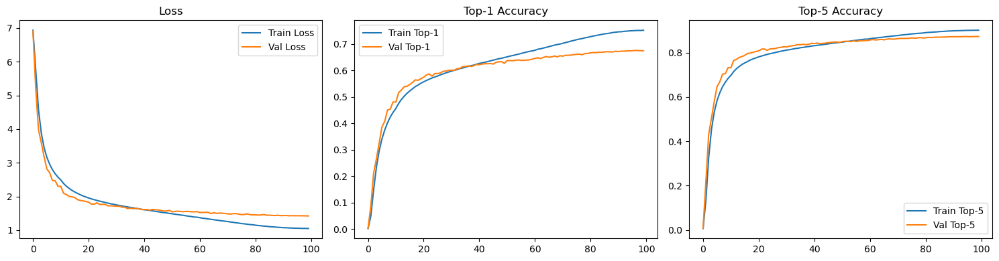

Evaluation:   0%|          | 0/196 [00:00<?, ?it/s]

/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/torch/_tensor.py:1362: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/c10/core/TensorImpl.h:1900.)
  return super().rename(names)


/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/torch/nn/modules/conv.py:456: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/torch/csrc/utils/python_arg_parser.cpp:368.)
  return F.conv2d(input, weight, bias, self.stride,
/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/brevitas/nn/quant_linear.py:69: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/torch/csrc/utils/python_arg_parser.cpp:368.)
  output_tensor = linear(x, quant_weight, quant_bias)
Evaluation:   1%|          | 1/196 [00:04<15:13,  4.68s/it]

Evaluation:   1%|          | 2/196 [00:05<06:57,  2.15s/it]

Evaluation:   2%|▏         | 3/196 [00:05<04:17,  1.33s/it]

...

Evaluation:  98%|█████████▊| 193/196 [00:41<00:00,  5.30it/s]

Evaluation:  99%|█████████▉| 194/196 [00:41<00:00,  5.30it/s]

Evaluation:  99%|█████████▉| 195/196 [00:42<00:00,  5.30it/s]

Evaluation: 100%|██████████| 196/196 [00:42<00:00,  4.64it/s]

Final Test Loss: 1.4210, Top-1: 0.6744, Top-5: 0.8723
🏆 Best Config: batch512_lr_max_0.01_min_1e-05_dp0.0 Top-1: 0.6744 Top-5: 0.8723


In [21]:
best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path = Hyperparameter_searching(epochs, warmup, batch_sizes, lr_max_pool, lr_min_pool, dropout_rates, plot_enable=True)

In [22]:
best_evaluation(best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path)

Best model loaded.


Evaluation:   0%|          | 0/196 [00:00<?, ?it/s]

Evaluation:   1%|          | 1/196 [00:02<07:27,  2.29s/it]

Evaluation:   1%|          | 2/196 [00:02<03:24,  1.06s/it]

Evaluation:   2%|▏         | 3/196 [00:02<02:07,  1.51it/s]

...

Evaluation:  99%|█████████▉| 194/196 [01:46<00:01,  1.85it/s]

Evaluation:  99%|█████████▉| 195/196 [01:46<00:00,  1.85it/s]

Evaluation: 100%|██████████| 196/196 [01:47<00:00,  1.98it/s]

Evaluation: 100%|██████████| 196/196 [01:47<00:00,  1.83it/s]

APoT-PWLF Test Loss: 153.1069 Top-1: 0.0010 Top-5: 0.0048


